In [1]:
from typing import TypedDict, Annotated, Literal
import operator
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
import os

load_dotenv()

True

In [3]:
PASS_SCORE = 8   # stop when the average score reaches this
MAX_TRIES = 5    # stop after this many evaluation rounds

model = ChatOpenAI(model=os.getenv('OPENAI_MODEL', 'gpt-4o-mini'))

class Evaluation(BaseModel):
    feedback: str = Field(description='Short, specific feedback on this aspect')
    score: int = Field(ge=0, le=10, description='Score from 0 to 10')

evaluator = model.with_structured_output(Evaluation)

In [4]:
class EssayState(TypedDict):
    essay: str
    correctness_score: int
    language_score: int
    word_choice_score: int
    correctness_feedback: str
    language_feedback: str
    word_choice_feedback: str
    average_score: float
    iteration: int
    history: Annotated[list[dict], operator.add]   # one entry per round

In [5]:
# Three evaluators. Each has its own score key, so every round overwrites
# the previous round's values instead of piling up.

def evaluate_correctness(state: EssayState):
    essay = state['essay']
    prompt = ('Evaluate the correctness of this essay: factual accuracy, logic, '
              f'and whether the arguments hold up.\n\n{essay}')
    r = evaluator.invoke(prompt)
    return {'correctness_feedback': r.feedback, 'correctness_score': r.score}

def evaluate_language(state: EssayState):
    essay = state['essay']
    prompt = ('Evaluate the language quality of this essay: grammar, spelling, '
              f'punctuation, sentence structure and flow.\n\n{essay}')
    r = evaluator.invoke(prompt)
    return {'language_feedback': r.feedback, 'language_score': r.score}

def evaluate_word_choice(state: EssayState):
    essay = state['essay']
    prompt = ('Evaluate the word selection in this essay: vocabulary, precision, '
              f'tone and repetition.\n\n{essay}')
    r = evaluator.invoke(prompt)
    return {'word_choice_feedback': r.feedback, 'word_choice_score': r.score}

In [6]:
def aggregate(state: EssayState):
    scores = [state['correctness_score'], state['language_score'], state['word_choice_score']]
    avg = sum(scores) / len(scores)
    n = state['iteration'] + 1
    return {
        'average_score': avg,
        'iteration': n,
        'history': [{'round': n, 'scores': scores, 'average': round(avg, 2), 'essay': state['essay']}],
    }

def route(state: EssayState) -> Literal['improve', 'done']:
    if state['average_score'] >= PASS_SCORE or state['iteration'] >= MAX_TRIES:
        return 'done'
    return 'improve'

In [7]:
def improve_essay(state: EssayState):
    essay = state['essay']
    prompt = (
        'Rewrite the essay below so it fixes the problems in the feedback. '
        'Keep the original meaning and a similar length. '
        'Return only the rewritten essay, with no commentary.\n\n'
        f'Correctness feedback: {state["correctness_feedback"]}\n'
        f'Language feedback: {state["language_feedback"]}\n'
        f'Word choice feedback: {state["word_choice_feedback"]}\n\n'
        f'Essay:\n{essay}'
    )
    return {'essay': model.invoke(prompt).content.strip()}

In [8]:
graph = StateGraph(EssayState)

graph.add_node('evaluate_correctness', evaluate_correctness)
graph.add_node('evaluate_language', evaluate_language)
graph.add_node('evaluate_word_choice', evaluate_word_choice)
graph.add_node('aggregate', aggregate)
graph.add_node('improve_essay', improve_essay)

evaluators = ['evaluate_correctness', 'evaluate_language', 'evaluate_word_choice']

# fan-out: first round starts from the user's essay
for name in evaluators:
    graph.add_edge(START, name)

# fan-in: wait for all three evaluators
graph.add_edge(evaluators, 'aggregate')

# loop or stop
graph.add_conditional_edges('aggregate', route, {'improve': 'improve_essay', 'done': END})

# loop back: the rewritten essay is evaluated again
for name in evaluators:
    graph.add_edge('improve_essay', name)

workflow = graph.compile()

In [11]:
essay = """Human life is a precious journey filled with learning, growth, and new experiences, It brings moments of joy and success alongside challenges that test our strength.
Our relationships with family, friends, and society give life deeper meaning, Kindness, empathy, and helping others help us make the world a better place, We should cherish every day, stay grateful, and use our talents wisely"""

result = workflow.invoke({'essay': essay, 'iteration': 0, 'history': []})

for h in result['history']:
    print(f"Round {h['round']}: scores={h['scores']} average={h['average']}")

print('\nFinal essay:\n')
print(result['essay'])
print('\nFinal average score:', result['average_score'], '| rounds used:', result['iteration'])

Round 1: scores=[6, 4, 6] average=5.33
Round 2: scores=[7, 8, 8] average=7.67
Round 3: scores=[8, 9, 8] average=8.33

Final essay:

Human life is a valuable journey rich with opportunities for learning, growth, and unique experiences. It includes moments of joy and achievement, along with challenges that test our resilience. The connections we form with family, friends, and our larger community infuse our existence with profound significance. For example, acts of kindness and empathy—such as volunteering at a homeless shelter or actively listening to a friend who is going through a tough time—can create lasting positive effects on those we engage with. Research shows that such community involvement not only helps others but also enhances our own well-being. Therefore, we should embrace each day, nurture a sense of gratitude, and purposefully share our talents to enhance not only our own lives but also uplift the lives of others around us.

Final average score: 8.333333333333334 | round

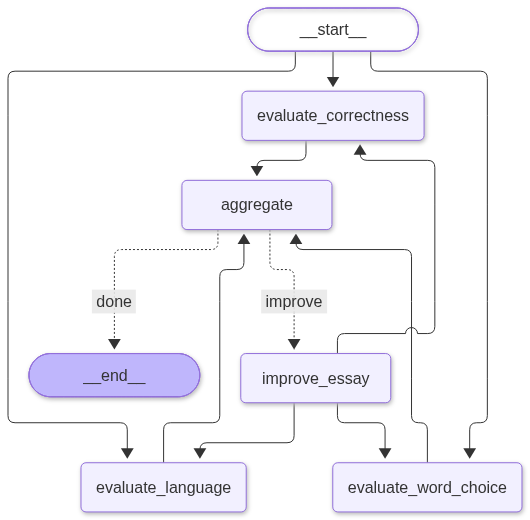

In [10]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())